# 🦌 Doñana — 2. Entrenamiento de un detector de animales con PyTorch

Adaptación del notebook de entrenamiento de clase (robots) al dataset de Doñana. Cambios principales:

| Plantilla (robots) | Doñana |
|---|---|
| 1 clase (`num_classes = 2`) | Una clase por especie/familia + fondo |
| Anotaciones XML por secuencia | `processed/annotations_*.csv` (de `01_preparar_datos.ipynb`) |
| `random_split` 80/20 | Split fijo por ráfagas y estratificado por clase (el test no se toca hasta `03_test`) |
| `Normalize(mean, std)` en el dataset | Solo `[0, 1]`: el modelo de torchvision ya normaliza internamente (normalizar dos veces perjudica) |
| `torch.stack(images)` | Lista de imágenes (pueden tener tamaños distintos) |
| Guarda el modelo con menor pérdida de **train** | Guarda el de mayor **mAP en validación** + `last.pt` para reanudar |

El código común (dataset, modelos, bucle de entrenamiento, métricas) está en `donana_det.py`, para reutilizarlo en
`04_data_augmentation.ipynb` exactamente igual.

## Instalación e imports
*Entorno de ejecución → Cambiar tipo → GPU (T4)*.

In [1]:
!pip install -q -U "albumentations>=2.0.5" torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 14.1 MB/s eta 0:00:00


In [2]:
import sys
from pathlib import Path

RUNNING_IN_COLAB = "google.colab" in sys.modules
if RUNNING_IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/donana")  # donana_data.py, donana_det.py y processed/ están aquí
    LOCAL_DIR = Path("/content")                         # disco local de Colab (rápido)
else:
    PROJECT_DIR = Path.cwd()
    LOCAL_DIR = Path.cwd()
sys.path.append(str(PROJECT_DIR))

PROCESSED_DIR = PROJECT_DIR / "processed"            # anotaciones, splits y caché comprimida
MODELS_DIR = PROJECT_DIR / "models"                  # checkpoints (en Drive, sobreviven a desconexiones)
IMAGES_DIR = LOCAL_DIR / "dona_24_1024"              # imágenes reducidas (lado mayor 1024 px)
CACHE_ZIP = PROCESSED_DIR / "dona_24_1024.zip"

import json
import numpy as np
import pandas as pd
import torch
import donana_data as dd
import donana_det as det

dd.ensure_image_cache(IMAGES_DIR, CACHE_ZIP)
annotations = pd.read_csv(PROCESSED_DIR / "annotations.csv")
CLASS_NAMES = json.loads((PROCESSED_DIR / "dataset_info.json").read_text())["class_names"]
NUM_CLASSES = len(CLASS_NAMES) + 1   # + fondo (clase 0)
train_df = annotations[annotations["split"] == "train"]
valid_df = annotations[annotations["split"] == "valid"]
test_df = annotations[annotations["split"] == "test"]
print(f"Clases ({NUM_CLASSES - 1}): {CLASS_NAMES}")
print(f"train {len(train_df)} | valid {len(valid_df)} | test {len(test_df)}")

Mounted at /content/drive
Descomprimiendo /content/drive/MyDrive/donana/processed/dona_24_1024.zip -> /content ...
Hecho
Clases (10): ['Cérvido', 'Jabalí', 'Vaca', 'Lepórido', 'Zorro', 'Tejón', 'Caballo', 'Meloncillo', 'Gineta', 'Lince']
train 3587 | valid 522 | test 1081


## Parámetros

| Parámetro | Qué hace |
|---|---|
| `model_name` | Arquitectura. `faster_rcnn_v1` (ResNet50-FPN) es una buena base; `faster_rcnn_v3` (MobileNetV3) es ~3-4× más rápido pero menos preciso. |
| `image_size` | Lado mayor con el que el modelo procesa la imagen. Más grande ayuda con animales pequeños/lejanos (conejos, ginetas), pero es más lento. |
| `num_epochs` | Pasadas completas por el train. Con `early_stopping_patience` se para antes si el mAP de validación deja de mejorar. |
| `batch_size` | Imágenes por paso. Limitado por la memoria de la GPU (4 cabe bien en una T4 a 1024 px con AMP). |
| `lr` | Learning rate del SGD. Regla de torchvision: 0.02 para batch 16 → 0.005 para batch 4. |
| `lr_momentum` | Inercia del SGD: promedia los gradientes recientes y suaviza la actualización. |
| `lr_decay` | *Weight decay* (regularización L2): penaliza pesos grandes para reducir sobreajuste. |
| `lr_factor`, `lr_patience`, `lr_threshold`, `lr_min` | `ReduceLROnPlateau`: si el mAP de validación no mejora más de `lr_threshold` en `lr_patience` épocas, `lr *= lr_factor` (hasta `lr_min`). |
| `max_grad_norm` | Recorte de la norma del gradiente (0 = sin recorte). Útil en RetinaNet/SSD, que a veces dan pérdidas `nan` al principio. |
| `use_amp` | Precisión mixta en GPU: ~2× más rápido y menos memoria. |

In [3]:
seed = 0
det.set_seed(seed)

# Modelo
model_name = "faster_rcnn_v1"
pretrained = True                    # pesos preentrenados en COCO
image_size = 1024

# Entrenamiento
use_gpu = True
use_amp = True
num_workers = 2                      # Colab tiene 2 CPU
num_epochs = 15
early_stopping_patience = 5
batch_size = 4
lr = 0.005
lr_momentum = 0.9
lr_decay = 1e-4
lr_factor = 0.1
lr_patience = 2
lr_threshold = 1e-3
lr_min = 1e-5
models_to_clip = ["retinanet_v1", "retinanet_v2", "ssd_v1", "ssd_v2"]
max_grad_norm = 1.0 if model_name in models_to_clip else 0.0

experiment_name = f"{model_name}_baseline"
output_dir = MODELS_DIR / experiment_name
config = dict(model_name=model_name, num_classes=NUM_CLASSES, image_size=image_size, class_names=CLASS_NAMES,
              batch_size=batch_size, lr=lr, augmentation=None, num_augments=0, seed=seed)

## Datos
Dataset = cómo cargar **una** imagen y su anotación; DataLoader = cómo agruparlas en batches (y en paralelo).

In [4]:
train_set = det.DonanaDataset(train_df, IMAGES_DIR)      # sin aumentación (baseline)
valid_set = det.DonanaDataset(valid_df, IMAGES_DIR)

train_loader = det.make_loader(train_set, batch_size, shuffle=True, num_workers=num_workers, seed=seed)
valid_loader = det.make_loader(valid_set, batch_size, shuffle=False, num_workers=num_workers)

image, target = train_set[0]
print(image.shape, target)

torch.Size([3, 576, 1024]) {'boxes': tensor([[194.4576, 262.7712, 290.4064, 328.8960]]), 'labels': tensor([4])}


## Modelo, optimizador y scheduler

In [5]:
device = det.get_device(use_gpu)
model = det.torchvision_model(model_name, NUM_CLASSES, pretrained=pretrained, image_size=image_size).to(device)
optimizer = det.build_optimizer(model, lr=lr, momentum=lr_momentum, weight_decay=lr_decay)
lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=lr_factor, patience=lr_patience, threshold=lr_threshold, min_lr=lr_min
)
print(f"Dispositivo: {device} | salida: {output_dir}")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 171MB/s]


Dispositivo: cuda | salida: /content/drive/MyDrive/donana/models/faster_rcnn_v1_baseline


## Entrenamiento
En cada época: entrenamiento → pérdida de validación → mAP de validación. Si Colab se desconecta, vuelve a ejecutar
el notebook: `fit` detecta `last.pt` y **reanuda** donde lo dejó.

El bucle (en `det.train_one_epoch`) es el mismo de la plantilla con los huecos rellenados:
```python
loss_dict = model(images, targets)
loss = sum(loss_dict.values())
optimizer.zero_grad()        # Reset gradients
loss.backward()              # Backpropagation
clip_grad_norm_(...)         # Clip gradients
optimizer.step()             # Update weights
```

In [6]:
history = det.fit(
    model, optimizer, lr_scheduler, train_loader, valid_loader, device,
    num_epochs=num_epochs, output_dir=output_dir, config=config,
    early_stopping_patience=early_stopping_patience, use_amp=use_amp, max_grad_norm=max_grad_norm,
)

Train:   0%|          | 0/897 [00:00<?, ?it/s]

Val loss:   0%|          | 0/131 [00:00<?, ?it/s]

Predict:   0%|          | 0/131 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dd9d71f6ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dd9d71f6ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Época   1/15 | train loss 0.1285 | valid loss 0.0952 | valid mAP 0.3693 | mAP@50 0.5306 | lr 5.0e-03  <- mejor


...

Train:   0%|          | 0/897 [00:00<?, ?it/s]

Val loss:   0%|          | 0/131 [00:00<?, ?it/s]

Predict:   0%|          | 0/131 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dd9d71f6ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7dd9d71f6ca0>if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
assert self._parent_pid == os.getpid(), 'can only test a child process'    
AssertionErrorself._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

: can only test a child process    if w.is_alive():

Exception ignored

Época  15/15 | train loss 0.0110 | valid loss 0.0580 | valid mAP 0.6047 | mAP@50 0.7386 | lr 5.0e-05


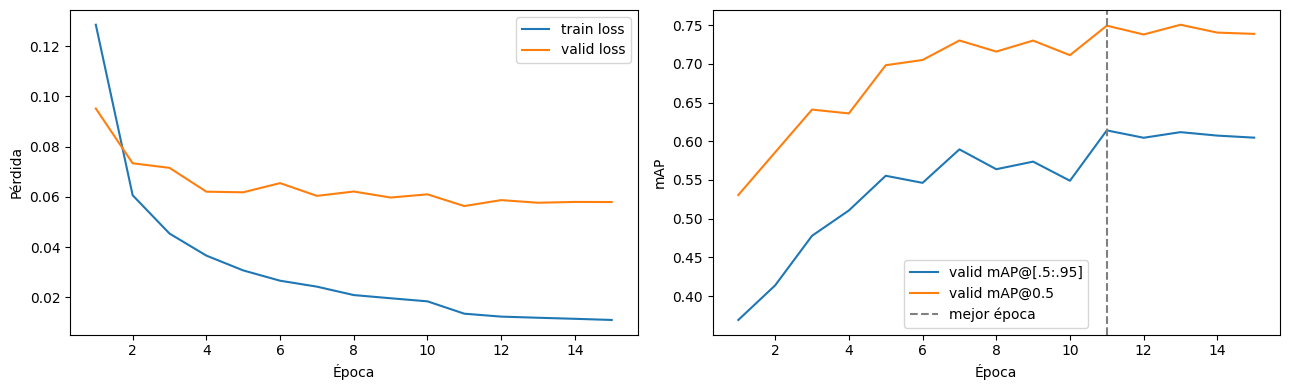

In [7]:
det.plot_history(history, save_path=output_dir / "history.png")

**Cómo leer la gráfica:** si la pérdida de train sigue bajando pero la de validación sube o el mAP de validación se
estanca, el modelo está **sobreajustando** (memoriza el train). Ese es justo el caso en el que la aumentación de datos
(`04_data_augmentation.ipynb`) suele ayudar.

## Resultado en validación (mejor modelo)

In [8]:
best_model, _ = det.load_trained_model(output_dir / "best.pt", device)
valid_results = det.evaluate(best_model, valid_loader, device, CLASS_NAMES)
print(f"Mejor época: {history['best_epoch']}")
pd.Series(det.summary_row(valid_results)).round(4).to_frame("valid")

Predict:   0%|          | 0/131 [00:00<?, ?it/s]

Mejor época: 11


,valid
mAP,0.6106
mAP@50,0.7447
mAP@75,0.6932
mAP agnóstico,0.8219
mAP@50 agnóstico,0.9849
Localización,0.9828
Acierto especie,0.9310
